In [1]:

!pip install -q xgboost scikit-learn pandas matplotlib


In [2]:

from google.colab import files
uploaded = files.upload()


Saving merged_music_cleaned.csv to merged_music_cleaned.csv


In [3]:

import pandas as pd

df = pd.read_csv("merged_music_cleaned.csv")

print(df.shape)
display(df.head())


(113549, 43)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,Stream,EnergyLiveness,Album,Album_type,Title,Channel,Licensed,official_video,most_playedon,youtube_match
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73.0,230666.0,False,0.676,0.4610,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55.0,149610.0,False,0.420,0.1660,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57.0,210826.0,False,0.438,0.3590,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71.0,201933.0,False,0.266,0.0596,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82.0,198853.0,False,0.618,0.4430,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


In [4]:

features = [
    "duration_ms",
    "explicit",
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature",
    "track_genre"
]

X = df[features]
y = df["popularity"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)


Input shape: (113549, 15)
Target shape: (113549,)


In [5]:

from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=df["track_id"])
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training:", len(X_train))
print("Testing:", len(X_test))


Training: 90922
Testing: 22627


In [6]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

preprocessor = ColumnTransformer([
    ("genre", OneHotEncoder(handle_unknown="ignore"), ["track_genre"])
], remainder="passthrough")

model = Pipeline([
    ("preprocessor", preprocessor),
    ("xgboost", XGBRegressor(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


In [7]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))


MAE: 15.352
RMSE: 19.471
R2 Score: 0.239


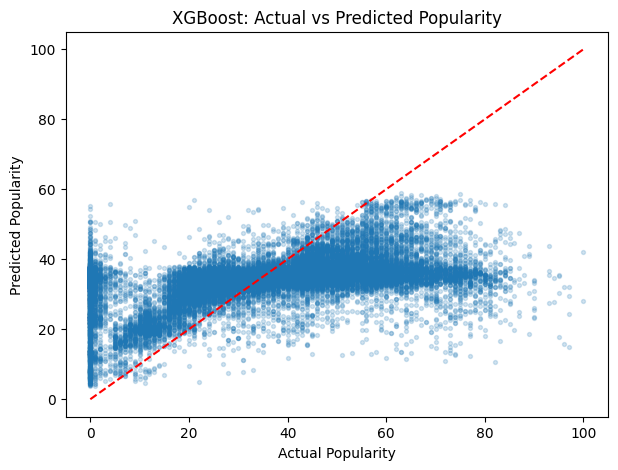

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.2, s=8)
plt.plot([0, 100], [0, 100], "r--")

plt.xlabel("Actual Popularity")
plt.ylabel("Predicted Popularity")
plt.title("XGBoost: Actual vs Predicted Popularity")
plt.show()


In [9]:

import joblib

joblib.dump(model, "xgboost_music_model.pkl")

files.download("xgboost_music_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Feature,Importance
59,genre__track_genre_iranian,0.043682
93,genre__track_genre_romance,0.041079
81,genre__track_genre_pop-film,0.036401
67,genre__track_genre_latin,0.031175
65,genre__track_genre_k-pop,0.030470
13,genre__track_genre_chicago-house,0.025238
64,genre__track_genre_jazz,0.025016
24,genre__track_genre_detroit-techno,0.025004
15,genre__track_genre_chill,0.024458
94,genre__track_genre_sad,0.023636


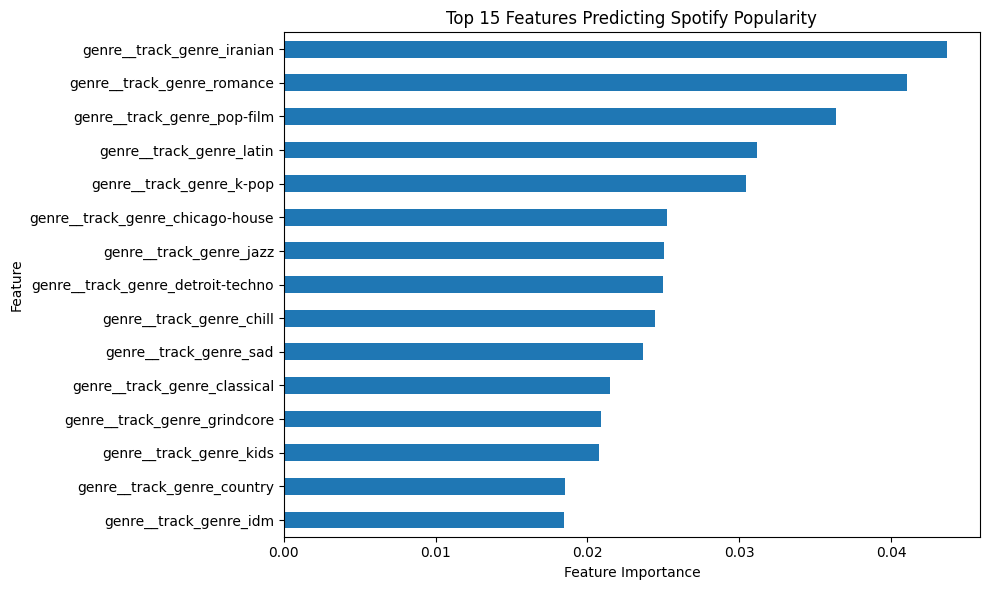

In [10]:

import pandas as pd
import matplotlib.pyplot as plt

feature_names = model.named_steps["preprocessor"].get_feature_names_out()

importance = model.named_steps["xgboost"].feature_importances_

feature_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_df = feature_df.sort_values(
    by="Importance",
    ascending=False
)

display(feature_df.head(15))

feature_df.head(15).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Top 15 Features Predicting Spotify Popularity")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


In [11]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

audio_features = [
    "duration_ms",
    "explicit",
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature"
]

X_train_audio = X_train[audio_features]
X_test_audio = X_test[audio_features]

audio_model = XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    objective="reg:squarederror"
)

audio_model.fit(X_train_audio, y_train)

audio_predictions = audio_model.predict(X_test_audio)

print("Audio Features Only - XGBoost")
print("MAE:", mean_absolute_error(y_test, audio_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, audio_predictions)))
print("R2:", r2_score(y_test, audio_predictions))

Audio Features Only - XGBoost
MAE: 17.03829695107676
RMSE: 20.88927371111519
R2: 0.12370584421115827


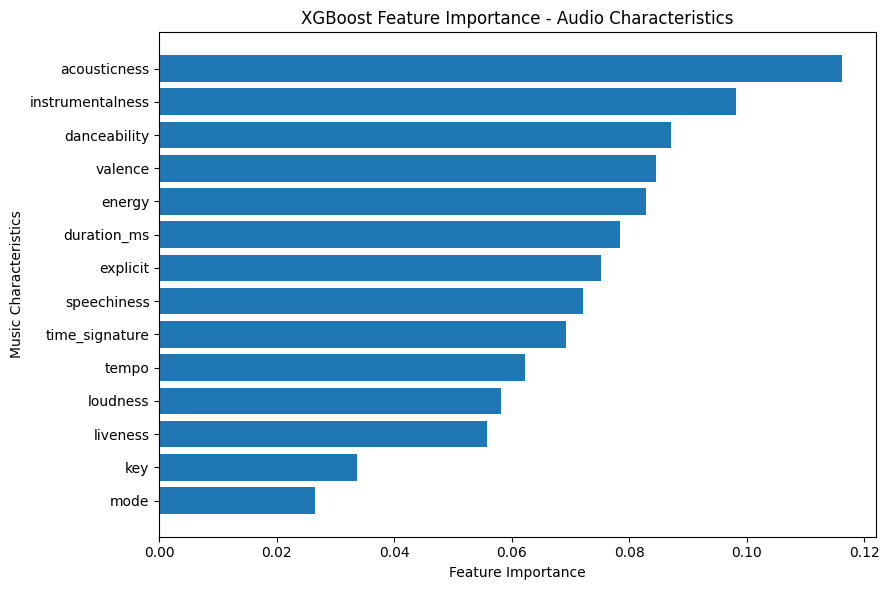

In [12]:

importance_df = pd.DataFrame({
    "Feature": audio_features,
    "Importance": audio_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title("XGBoost Feature Importance - Audio Characteristics")
plt.xlabel("Feature Importance")
plt.ylabel("Music Characteristics")
plt.tight_layout()
plt.show()


In [14]:
correlations = spotify[audio_features + ["popularity"]].corr()["popularity"]

correlations = correlations.drop("popularity").sort_values()

print(correlations)

plt.figure(figsize=(10, 6))

correlations.plot(kind="barh")

plt.title("Relationship Between Audio Features and Spotify Popularity")
plt.xlabel("Pearson Correlation")
plt.ylabel("Audio Characteristics")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()


NameError: name 'spotify' is not defined

instrumentalness   -0.127477
speechiness        -0.047086
acousticness       -0.038828
duration_ms        -0.023157
mode               -0.016238
liveness           -0.013857
valence            -0.011508
key                 0.003441
tempo               0.007280
energy              0.013725
time_signature      0.036898
explicit            0.054898
danceability        0.064275
loudness            0.071674
Name: popularity, dtype: float64


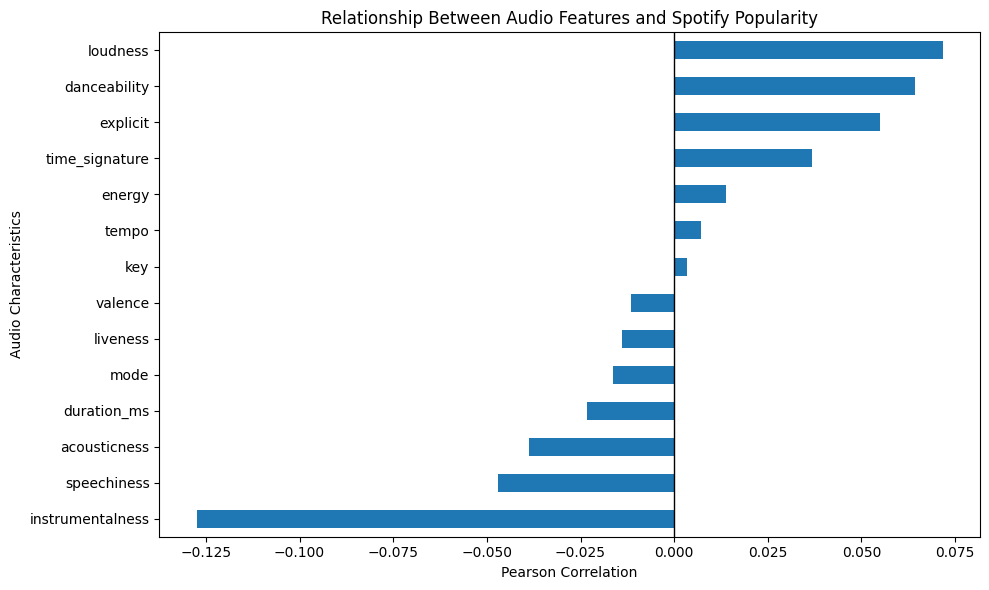

In [15]:

spotify = df.drop_duplicates(subset="track_id").copy()

correlations = spotify[audio_features + ["popularity"]].corr(numeric_only=True)["popularity"]

correlations = correlations.drop("popularity").sort_values()

print(correlations)

plt.figure(figsize=(10, 6))

correlations.plot(kind="barh")

plt.title("Relationship Between Audio Features and Spotify Popularity")
plt.xlabel("Pearson Correlation")
plt.ylabel("Audio Characteristics")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()


In [16]:
df = pd.read_csv("merged_music_cleaned.csv")

In [17]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

results = pd.DataFrame({
    "Model": ["Audio Only", "Audio + Genre"],
    "MAE": [
        mean_absolute_error(y_test, audio_predictions),
        mean_absolute_error(y_test, model.predict(X_test))
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, audio_predictions)),
        np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
    ],
    "R2": [
        r2_score(y_test, audio_predictions),
        r2_score(y_test, model.predict(X_test))
    ]
})

display(results.round(3))


,Model,MAE,RMSE,R2
0,Audio Only,17.038,20.889,0.124
1,Audio + Genre,15.352,19.471,0.239


In [18]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_model = LinearRegression()

linear_model.fit(X_train_audio, y_train)

linear_predictions = linear_model.predict(X_test_audio)

print("Linear Regression Results")
print("MAE:", round(mean_absolute_error(y_test, linear_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, linear_predictions)), 3))
print("R2:", round(r2_score(y_test, linear_predictions), 3))


Linear Regression Results
MAE: 18.384
RMSE: 22.011
R2: 0.027


In [19]:

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_genre_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_genre_model.fit(X_train, y_train)

linear_genre_predictions = linear_genre_model.predict(X_test)

print("Linear Regression (Audio + Genre)")
print("MAE:", round(mean_absolute_error(y_test, linear_genre_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, linear_genre_predictions)), 3))
print("R2:", round(r2_score(y_test, linear_genre_predictions), 3))


Linear Regression (Audio + Genre)
MAE: 18.823
RMSE: 22.285
R2: 0.003


In [20]:

from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10.0))
])

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

print("Ridge Regression (Audio + Genre)")
print("MAE:", round(mean_absolute_error(y_test, ridge_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, ridge_predictions)), 3))
print("R2:", round(r2_score(y_test, ridge_predictions), 3))


Ridge Regression (Audio + Genre)
MAE: 18.823
RMSE: 22.285
R2: 0.003


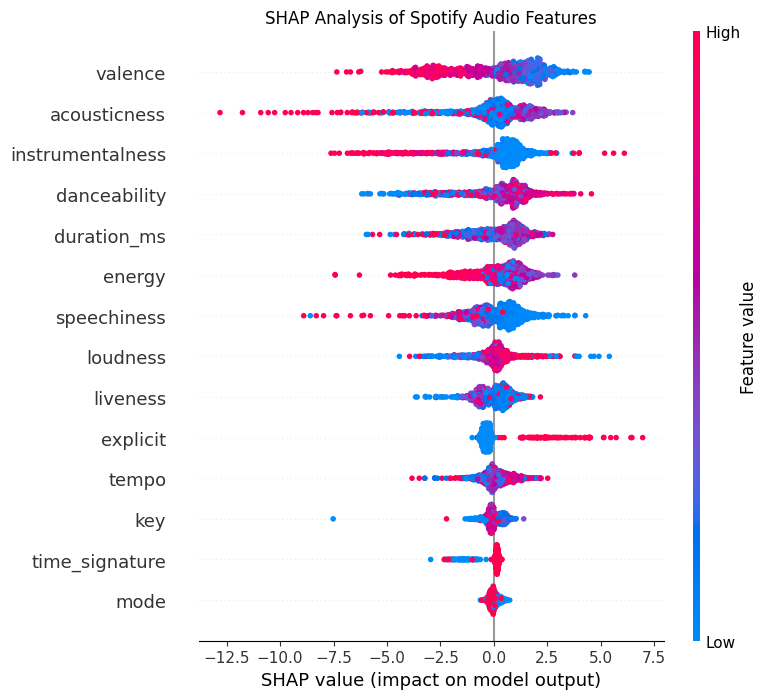

In [21]:

import shap
import matplotlib.pyplot as plt

sample = X_test_audio.sample(
    n=min(1000, len(X_test_audio)),
    random_state=42
)

explainer = shap.TreeExplainer(audio_model)

shap_values = explainer(sample)

shap.plots.beeswarm(
    shap_values,
    max_display=14,
    show=False
)

plt.title("SHAP Analysis of Spotify Audio Features")
plt.tight_layout()
plt.show()


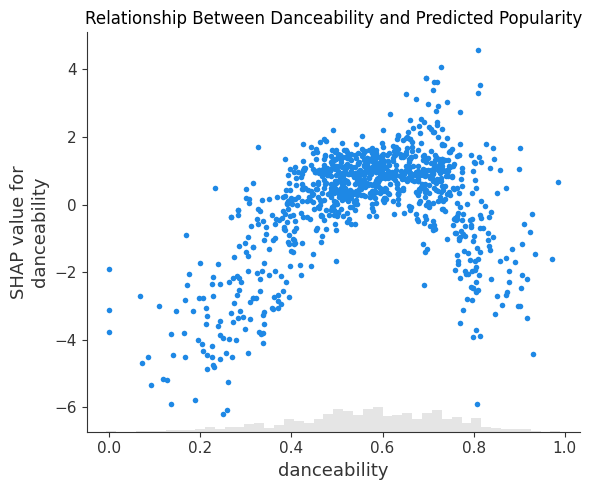

In [22]:

shap.plots.scatter(
    shap_values[:, "danceability"],
    show=False
)

plt.title("Relationship Between Danceability and Predicted Popularity")
plt.tight_layout()
plt.show()


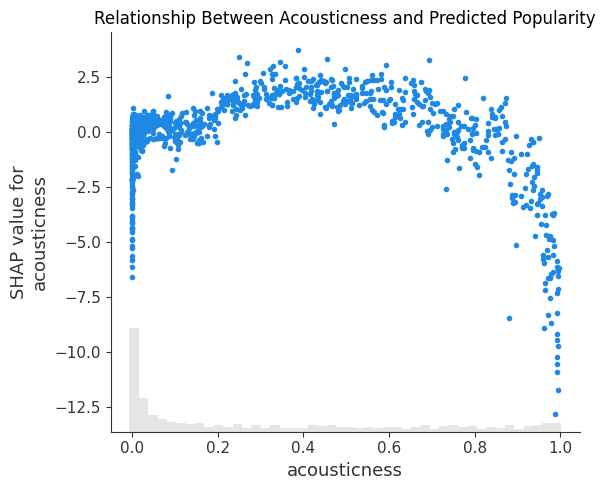

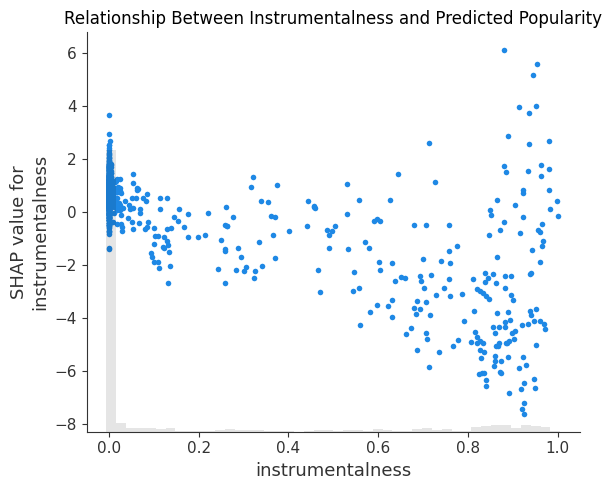

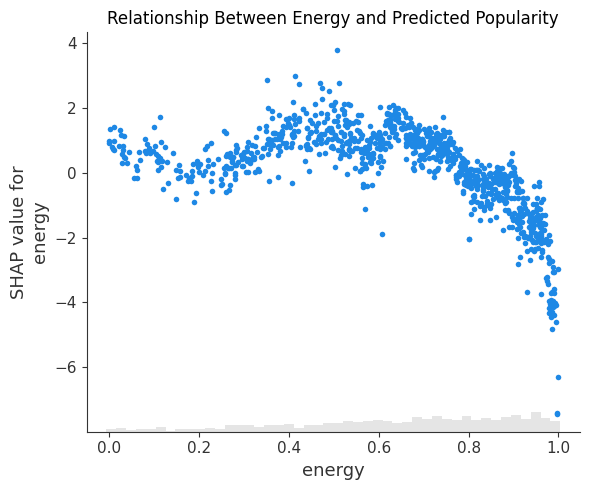

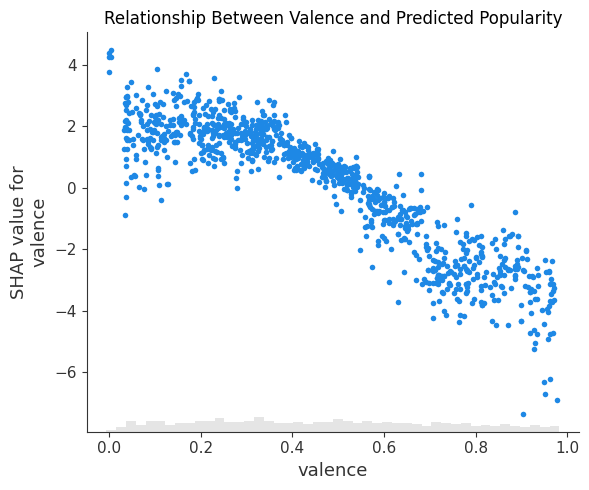

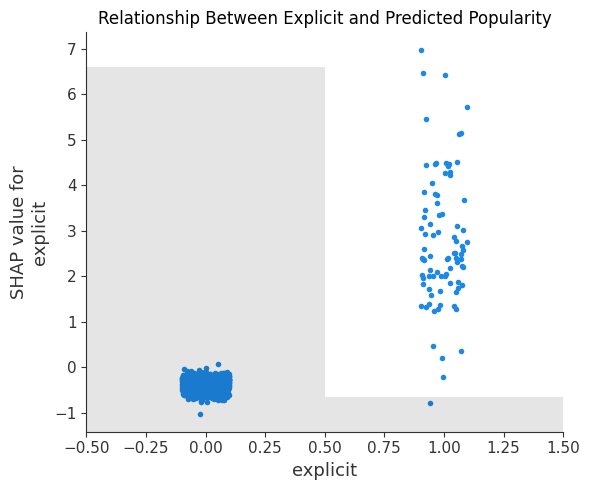

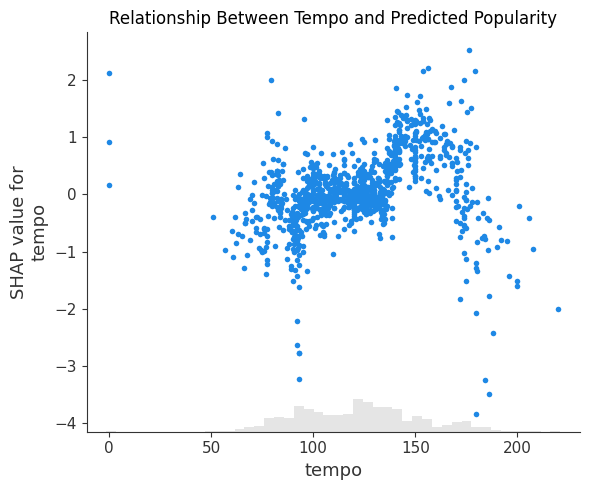

In [23]:

features_to_plot = [
    "acousticness",
    "instrumentalness",
    "energy",
    "valence",
    "explicit",
    "tempo"
]

for feature in features_to_plot:
    shap.plots.scatter(
        shap_values[:, feature],
        show=False
    )

    plt.title(f"Relationship Between {feature.title()} and Predicted Popularity")
    plt.tight_layout()
    plt.show()


In [24]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train_audio, y_train)

baseline_predictions = baseline.predict(X_test_audio)

print("Mean Baseline Results")
print("MAE:", round(mean_absolute_error(y_test, baseline_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, baseline_predictions)), 3))
print("R2:", round(r2_score(y_test, baseline_predictions), 3))


Mean Baseline Results
MAE: 18.866
RMSE: 22.321
R2: -0.0


In [25]:

train_ids = set(df.loc[X_train.index, "track_id"])
test_ids = set(df.loc[X_test.index, "track_id"])

overlap = train_ids.intersection(test_ids)

print("Training songs:", len(train_ids))
print("Testing songs:", len(test_ids))
print("Songs appearing in both:", len(overlap))

if len(overlap) == 0:
    print("No track ID overlap detected.")
else:
    print("Track ID overlap detected. We need to fix the split.")


Training songs: 71792
Testing songs: 17948
Songs appearing in both: 0
No track ID overlap detected.


In [26]:

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.base import clone
import pandas as pd

cv = GroupKFold(n_splits=5)

cv_results = cross_validate(
    clone(model),
    X_train,
    y_train,
    groups=df.loc[X_train.index, "track_id"],
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    },
    n_jobs=-1
)

cv_scores = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE": -cv_results["test_MAE"],
    "R2": cv_results["test_R2"]
})

display(cv_scores.round(3))

print("Average MAE:", round(cv_scores["MAE"].mean(), 3))
print("Average R2:", round(cv_scores["R2"].mean(), 3))


,Fold,MAE,R2
0,1,15.564,0.235
1,2,15.333,0.237
2,3,15.281,0.248
3,4,15.271,0.243
4,5,15.109,0.244


Average MAE: 15.312
Average R2: 0.242


In [27]:

from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.base import clone

param_grid = {
    "xgboost__n_estimators": [100, 200, 300, 400],
    "xgboost__max_depth": [3, 4, 5, 6],
    "xgboost__learning_rate": [0.03, 0.05, 0.1],
    "xgboost__subsample": [0.8, 1.0],
    "xgboost__colsample_bytree": [0.8, 1.0]
}

search = RandomizedSearchCV(
    estimator=clone(model),
    param_distributions=param_grid,
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=5),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

groups = df.loc[X_train.index, "track_id"]

search.fit(X_train, y_train, groups=groups)

print("Best Parameters:")
print(search.best_params_)

print("\nBest Cross-Validation MAE:")
print(round(-search.best_score_, 3))


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters:
{'xgboost__subsample': 0.8, 'xgboost__n_estimators': 400, 'xgboost__max_depth': 4, 'xgboost__learning_rate': 0.1, 'xgboost__colsample_bytree': 0.8}

Best Cross-Validation MAE:
13.623


In [28]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tuned_model = search.best_estimator_

tuned_predictions = tuned_model.predict(X_test)

print("Tuned XGBoost Test Results")
print("MAE:", round(mean_absolute_error(y_test, tuned_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, tuned_predictions)), 3))
print("R2:", round(r2_score(y_test, tuned_predictions), 3))


Tuned XGBoost Test Results
MAE: 13.656
RMSE: 18.489
R2: 0.314


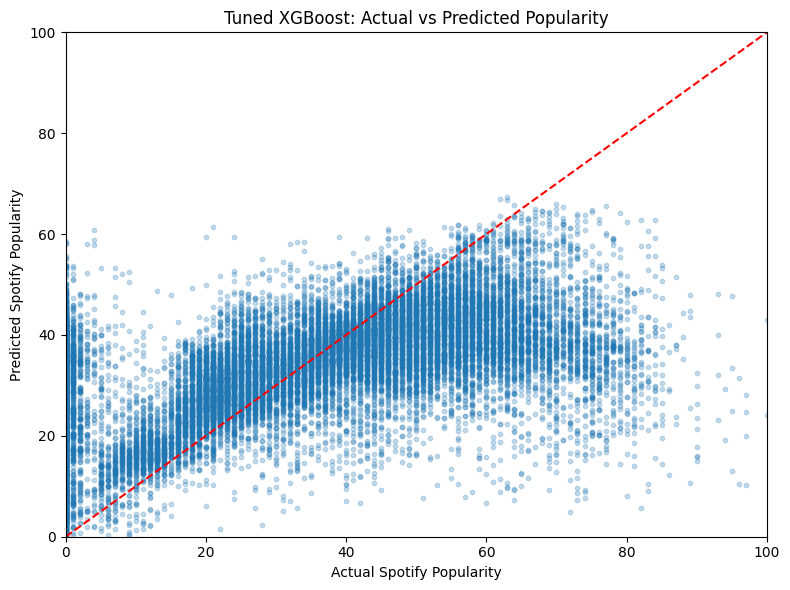

In [29]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    tuned_predictions,
    alpha=0.25,
    s=10
)

plt.plot([0, 100], [0, 100], "r--")

plt.xlabel("Actual Spotify Popularity")
plt.ylabel("Predicted Spotify Popularity")
plt.title("Tuned XGBoost: Actual vs Predicted Popularity")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


In [30]:

import joblib
from google.colab import files

joblib.dump(
    tuned_model,
    "xgboost_music_tuned.pkl"
)

files.download("xgboost_music_tuned.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>